# Day-Ahead Household Energy Forecasting with XGBoost

**Goal:** forecast the hourly electricity consumption of a single household **one day ahead**: at midnight, predict each of the next 24 hours.

**Data:** [UCI Individual Household Electric Power Consumption](https://www.kaggle.com/datasets/uciml/electric-power-consumption-data-set). That's 2,075,259 one-minute readings from a house near Paris (Dec 2006 – Nov 2010).

**Approach:**
1. Clean the raw minute data (missing values, long outages) and resample to hourly.
2. Build calendar, lag, and French public-holiday features **without future leakage**.
3. Compare XGBoost against two seasonal-naive baselines using **time-series cross-validation** on the final year.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import holidays
import xgboost as xgb
from pathlib import Path
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error

plt.style.use('seaborn-v0_8-whitegrid')
FIG_DIR = Path('figures'); FIG_DIR.mkdir(exist_ok=True)
SEED = 42

## 1. Load the raw data

In [2]:
raw = pd.read_csv('data/household_power_consumption.csv', sep=';',
                  na_values='?', low_memory=False)
raw.index = pd.to_datetime(raw['Date'] + ' ' + raw['Time'], format='%d/%m/%Y %H:%M:%S')
raw = raw.drop(columns=['Date', 'Time'])

print(f'{len(raw):,} rows | {raw.index.min()} → {raw.index.max()}')
raw.head()

2,075,259 rows | 2006-12-16 17:24:00 → 2010-11-26 21:02:00


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [3]:
# Missing values are stored as '?' in the raw file
raw.isna().mean().mul(100).round(2).rename('% missing')

Global_active_power      1.25
Global_reactive_power    1.25
Voltage                  1.25
Global_intensity         1.25
Sub_metering_1           1.25
Sub_metering_2           1.25
Sub_metering_3           1.25
Name: % missing, dtype: float64

## 2. Clean the data

About 1.25% of minutes are missing, but they aren't spread out evenly. Most gaps are short, and a few are **outages lasting several days**. Each kind needs different handling.

In [4]:
target = raw['Global_active_power']   # kW, minute average
is_na = target.isna()
gap_id = (is_na != is_na.shift()).cumsum()
gap_lengths = is_na.groupby(gap_id).sum()
gap_lengths = gap_lengths[gap_lengths > 0]

print(f'{len(gap_lengths)} gaps | longest: {gap_lengths.max()/60:.1f} h')
print(f'gaps > 1 h: {(gap_lengths > 60).sum()} | gaps > 24 h: {(gap_lengths > 1440).sum()}')

71 gaps | longest: 120.4 h
gaps > 1 h: 9 | gaps > 24 h: 6


**Cleaning strategy:**
- Resample to hourly means. The mean kW over one hour equals **kWh consumed in that hour**.
- An hour counts as valid only if at least 45 of its 60 minutes are present.
- Gaps of up to 3 h are filled by linear interpolation.
- Longer outages are filled with the value from the same hour one week earlier.
- Every imputed hour is **flagged and excluded from scoring**, so the model is never graded on made-up data.

In [5]:
counts = target.resample('h').count()
hourly = target.resample('h').mean()
hourly[counts < 45] = np.nan
hourly = hourly.loc['2006-12-16 18:00':'2010-11-26 20:00']   # complete hours only

imputed = hourly.isna()
hourly = hourly.interpolate(limit=3, limit_area='inside')
for _ in range(3):                       # repeat for outages longer than a week
    hourly = hourly.fillna(hourly.shift(168))

df = pd.DataFrame({'kwh': hourly, 'imputed': imputed})
print(f'{len(df):,} hourly rows | imputed: {imputed.sum()} ({imputed.mean():.1%}) | remaining NaN: {df.kwh.isna().sum()}')

34,587 hourly rows | imputed: 436 (1.3%) | remaining NaN: 0


## 3. Exploratory analysis

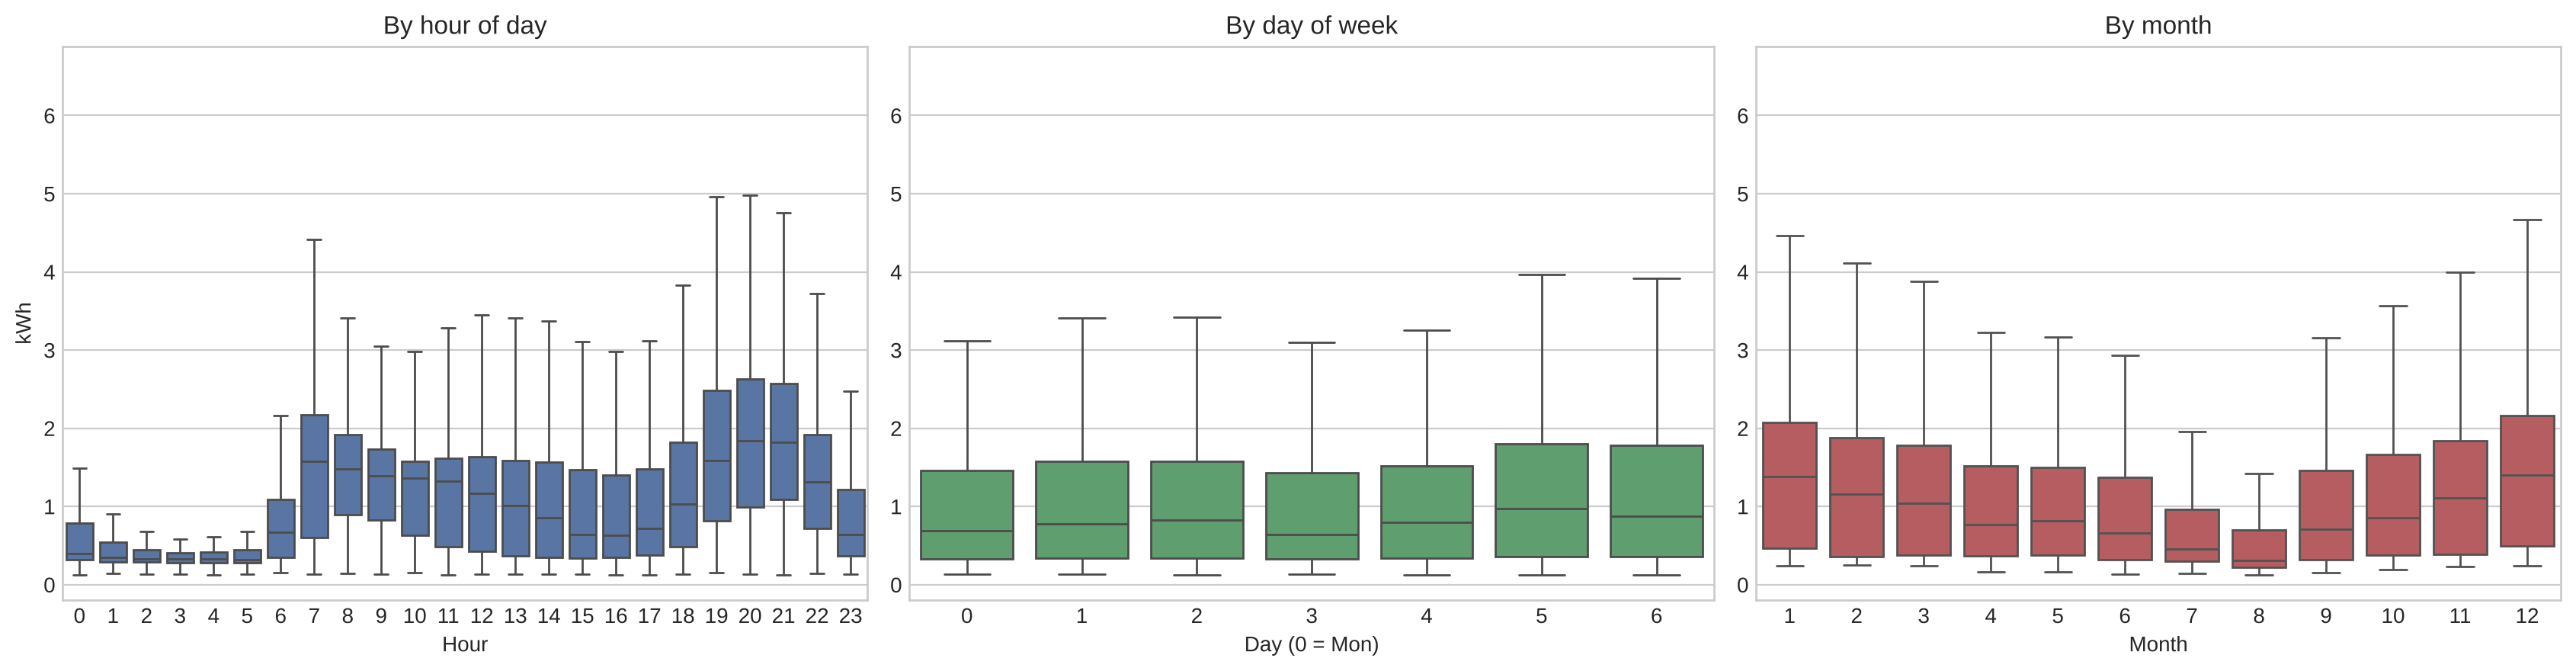

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(x=df.index.hour, y=df.kwh, ax=axes[0], color='#4C72B0', fliersize=0)
axes[0].set(title='By hour of day', xlabel='Hour', ylabel='kWh')
sns.boxplot(x=df.index.dayofweek, y=df.kwh, ax=axes[1], color='#55A868', fliersize=0)
axes[1].set(title='By day of week', xlabel='Day (0 = Mon)', ylabel='')
sns.boxplot(x=df.index.month, y=df.kwh, ax=axes[2], color='#C44E52', fliersize=0)
axes[2].set(title='By month', xlabel='Month', ylabel='')
plt.tight_layout(); plt.savefig(FIG_DIR / 'seasonality.png', dpi=120); plt.show()

Clear patterns show up. Consumption is low overnight, with a morning peak and a larger evening peak (around 19:00–21:00). Weekends run higher, and winter months use far more energy than summer (August is lowest, likely because of vacation). The wide boxes show how **noisy** a single household is, which sets a ceiling on how accurate any model can be.

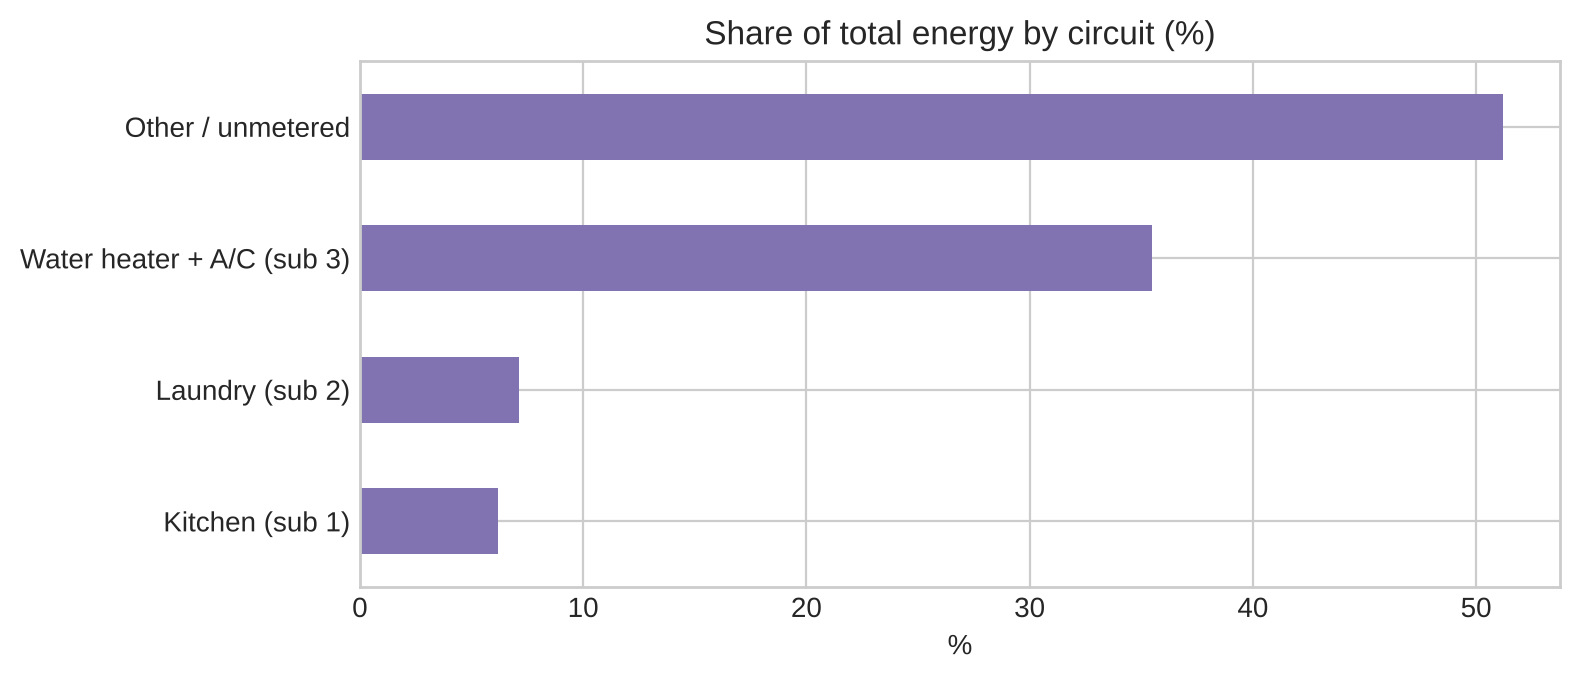

Kitchen (sub 1)                6.2
Laundry (sub 2)                7.1
Water heater + A/C (sub 3)    35.5
Other / unmetered             51.2
dtype: float64

In [7]:
# Sub-metering breakdown (Wh per minute). The rest of the active power is unmetered.
sub = raw[['Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']].sum()
total_wh = (raw['Global_active_power'] * 1000 / 60).sum()
shares = pd.Series({
    'Kitchen (sub 1)': sub.iloc[0], 'Laundry (sub 2)': sub.iloc[1],
    'Water heater + A/C (sub 3)': sub.iloc[2], 'Other / unmetered': total_wh - sub.sum()
}) / total_wh * 100
ax = shares.sort_values().plot(kind='barh', figsize=(8, 3.5), color='#8172B2')
ax.set(title='Share of total energy by circuit (%)', xlabel='%')
plt.tight_layout(); plt.savefig(FIG_DIR / 'submetering.png', dpi=120); plt.show()
shares.round(1)

## 4. Feature engineering

**Leakage rule:** in day-ahead forecasting, the forecast is made at midnight, so a feature can only use data from **yesterday or earlier**. That's why the shortest lag is 24 h. A 1-hour lag would look great in testing but couldn't be used in practice.

In [8]:
fr_holidays = holidays.France(years=range(2006, 2011))

def create_features(d):
    d = d.copy()
    idx = d.index
    # Calendar
    d['hour'] = idx.hour
    d['dayofweek'] = idx.dayofweek
    d['month'] = idx.month
    d['dayofyear'] = idx.dayofyear
    d['is_weekend'] = (idx.dayofweek >= 5).astype(int)
    d['is_holiday'] = np.isin(idx.normalize(), pd.to_datetime(list(fr_holidays.keys()))).astype(int)
    # Lags (all >= 24 h)
    d['lag_24h'] = d['kwh'].shift(24)
    d['lag_48h'] = d['kwh'].shift(48)
    d['lag_168h'] = d['kwh'].shift(168)
    # Yesterday's average and the trailing 7-day average (known at midnight)
    daily = d['kwh'].resample('D').mean()
    day = pd.Series(idx.normalize(), index=idx)
    d['prev_day_mean'] = day.map(daily.shift(1)).values
    d['prev_week_mean'] = day.map(daily.rolling(7).mean().shift(1)).values
    return d

data = create_features(df).dropna()
CALENDAR = ['hour', 'dayofweek', 'month', 'dayofyear', 'is_weekend']
LAGS = ['lag_24h', 'lag_48h', 'lag_168h', 'prev_day_mean', 'prev_week_mean']
FEATURE_SETS = {
    'XGB: calendar only': CALENDAR,
    'XGB: + lags': CALENDAR + LAGS,
    'XGB: + lags + holidays': CALENDAR + LAGS + ['is_holiday'],
}
print(f'{len(data):,} rows after feature creation | holidays flagged: {data.is_holiday.sum() // 24} days')

34,419 rows after feature creation | holidays flagged: 42 days


## 5. Validation setup

- **Time-series cross-validation:** 5 folds, each testing on the next 73 days, so the folds together cover the final year. The model only ever trains on the past.
- **Early stopping uses the last 30 days of each training window**, never the test fold, so test data doesn't leak into model selection.
- **Baselines:** *yesterday same hour* and *last week same hour*. A model is only worth deploying if it beats these.

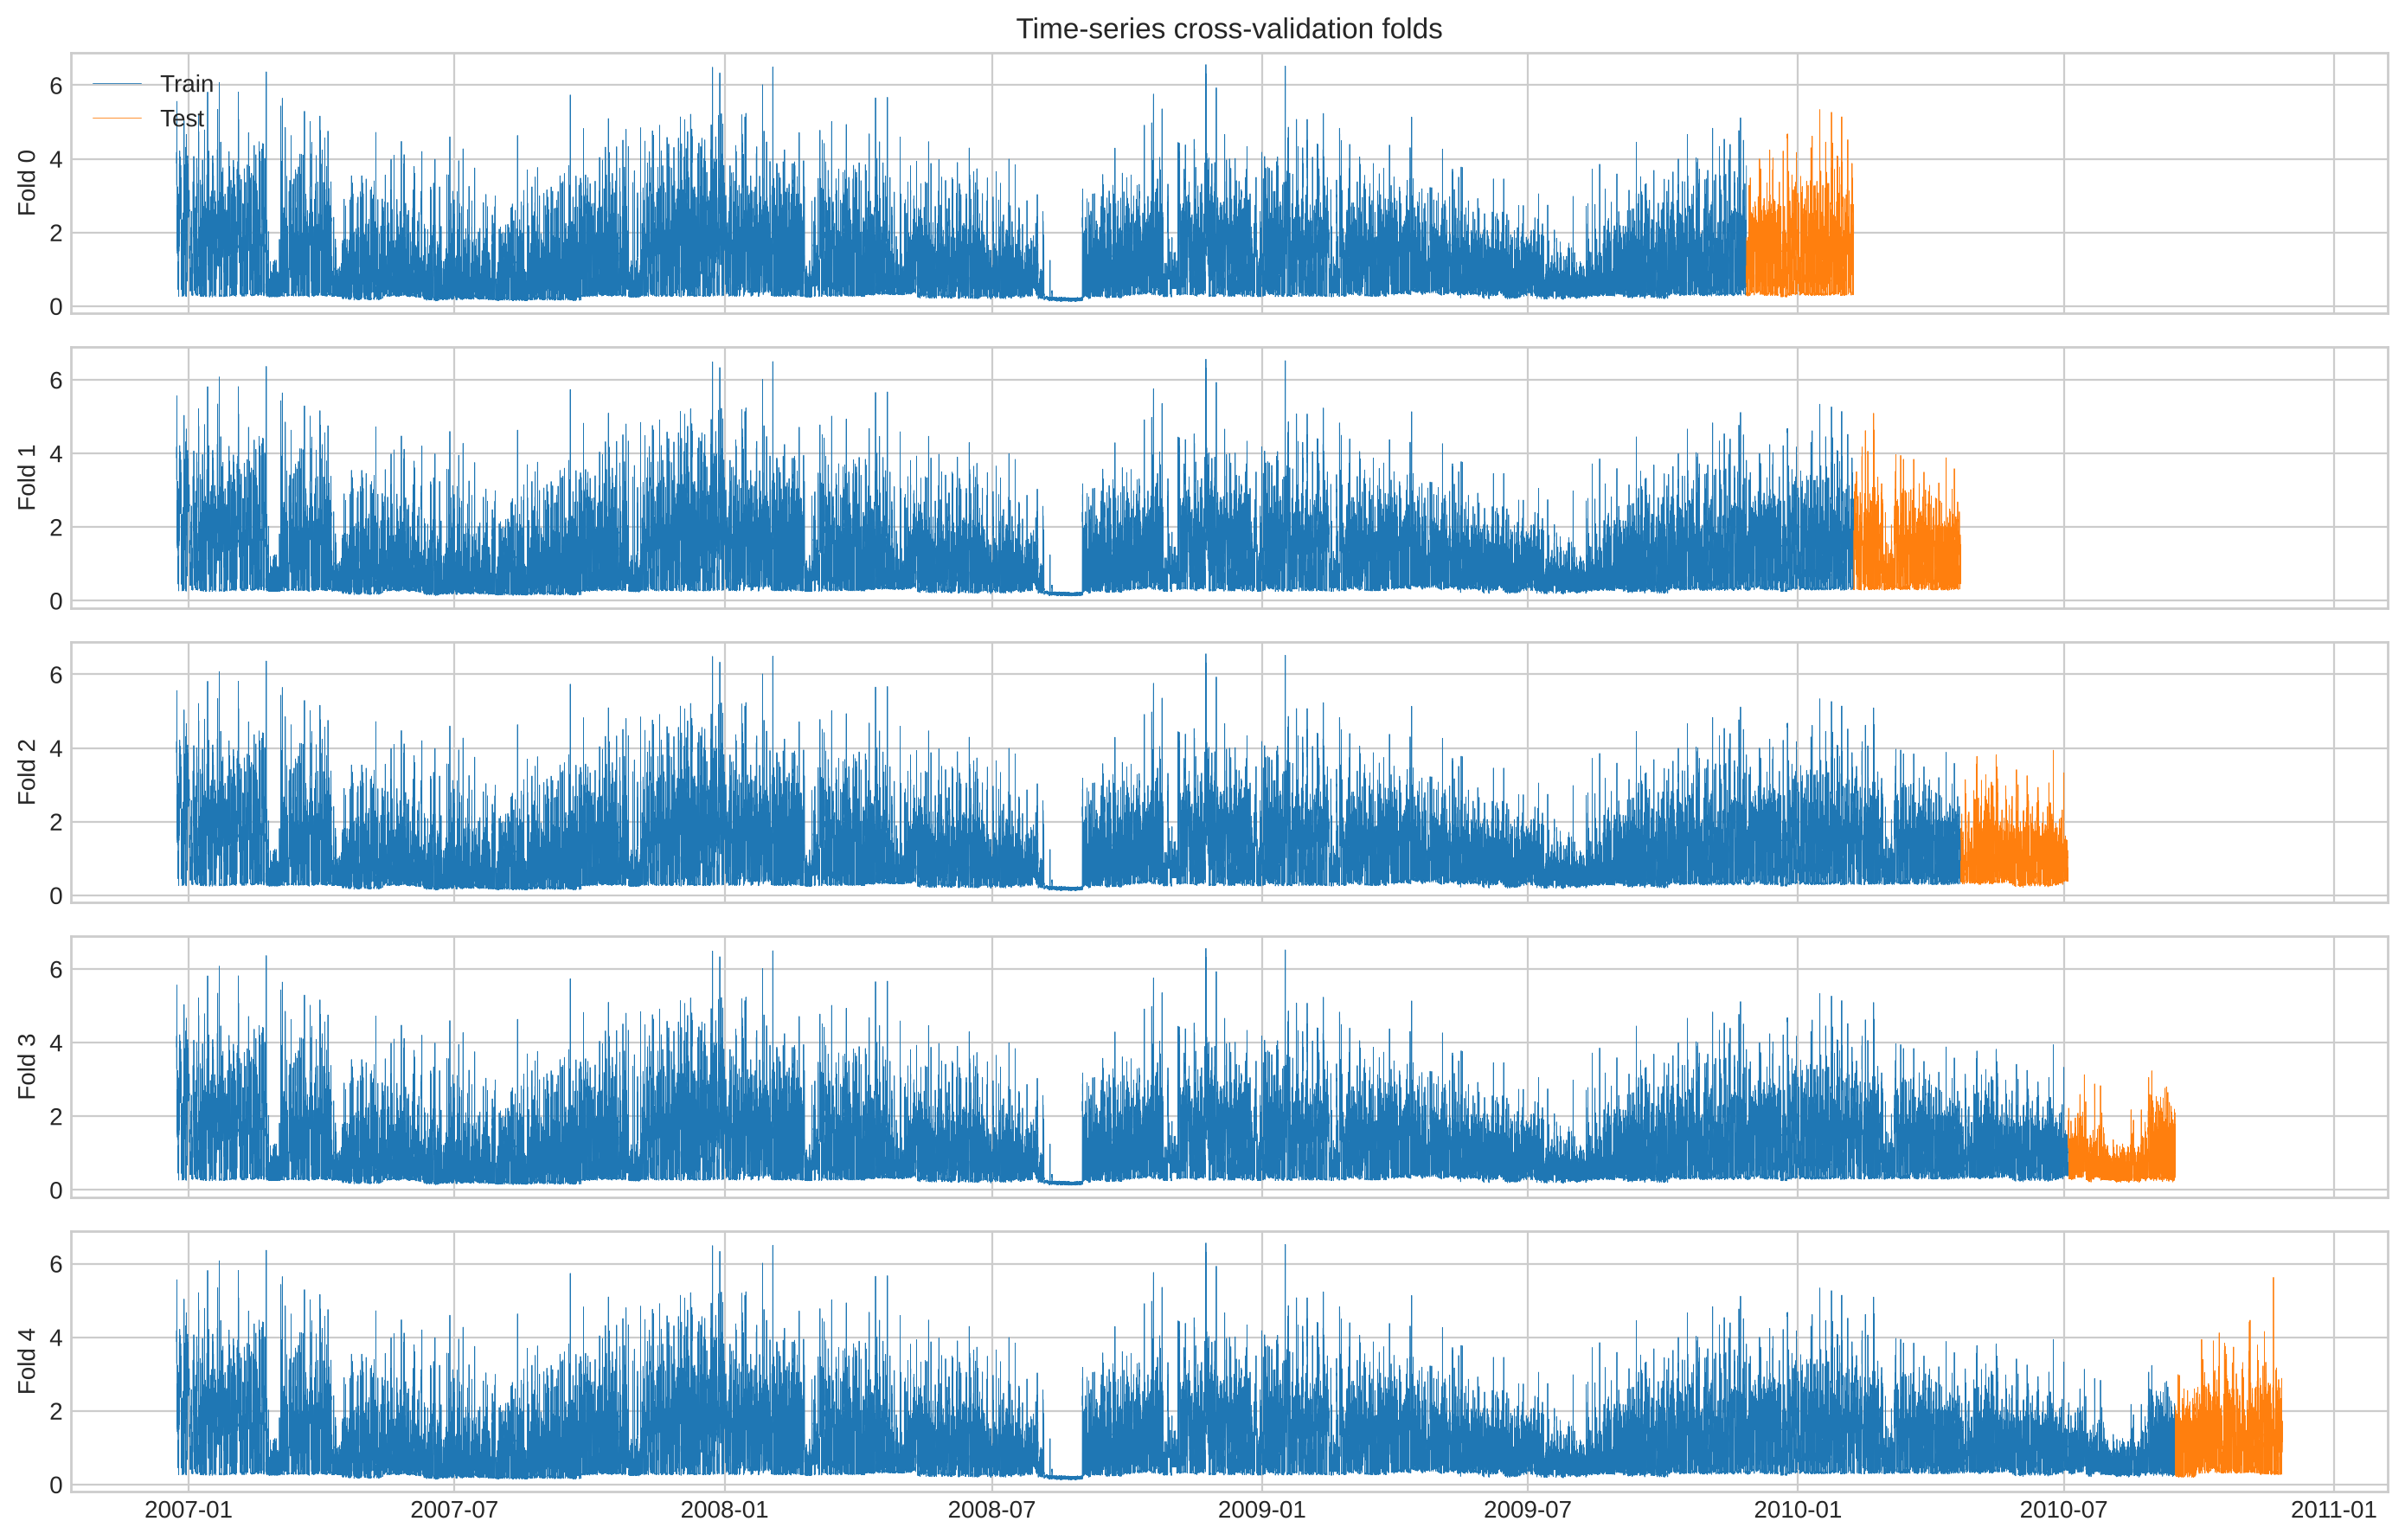

In [9]:
tss = TimeSeriesSplit(n_splits=5, test_size=24 * 73)

fig, axes = plt.subplots(5, 1, figsize=(14, 9), sharex=True)
for fold, (tr, te) in enumerate(tss.split(data)):
    axes[fold].plot(data.index[tr], data.kwh.iloc[tr], lw=0.3, label='Train')
    axes[fold].plot(data.index[te], data.kwh.iloc[te], lw=0.3, label='Test')
    axes[fold].set_ylabel(f'Fold {fold}')
axes[0].legend(loc='upper left'); axes[0].set_title('Time-series cross-validation folds')
plt.tight_layout(); plt.savefig(FIG_DIR / 'cv_folds.png', dpi=120); plt.show()

## 6. Train and evaluate

In [10]:
XGB_PARAMS = dict(n_estimators=2000, learning_rate=0.03, max_depth=5, subsample=0.8,
                  colsample_bytree=0.8, objective='reg:squarederror',
                  early_stopping_rounds=100, random_state=SEED)

rows, oof = [], []
for fold, (tr, te) in enumerate(tss.split(data)):
    train, test = data.iloc[tr], data.iloc[te]
    mask = ~test['imputed']                     # score only on real measurements
    y_true = test.loc[mask, 'kwh']

    preds = {'Naive: yesterday': test['lag_24h'], 'Naive: last week': test['lag_168h']}

    fit, val = train.iloc[:-24 * 30], train.iloc[-24 * 30:]
    for name, feats in FEATURE_SETS.items():
        model = xgb.XGBRegressor(**XGB_PARAMS)
        model.fit(fit[feats], fit['kwh'], eval_set=[(val[feats], val['kwh'])], verbose=False)
        preds[name] = pd.Series(model.predict(test[feats]), index=test.index)

    for name, p in preds.items():
        rows.append({'fold': fold, 'model': name,
                     'RMSE': np.sqrt(mean_squared_error(y_true, p[mask])),
                     'MAE': mean_absolute_error(y_true, p[mask])})
    oof.append(pd.DataFrame({'actual': test['kwh'], 'imputed': test['imputed'],
                             'pred': preds['XGB: + lags + holidays'],
                             'naive': preds['Naive: yesterday']}))

scores = pd.DataFrame(rows)
oof = pd.concat(oof)

In [11]:
summary = scores.groupby('model')[['RMSE', 'MAE']].mean().sort_values('RMSE')
best_naive = summary.loc[['Naive: yesterday', 'Naive: last week'], 'RMSE'].min()
best_naive_mae = summary.loc[['Naive: yesterday', 'Naive: last week'], 'MAE'].min()
summary['RMSE vs best naive'] = (1 - summary['RMSE'] / best_naive).map('{:+.1%}'.format)
summary['MAE vs best naive'] = (1 - summary['MAE'] / best_naive_mae).map('{:+.1%}'.format)
summary.round(4)

,RMSE,MAE,RMSE vs best naive,MAE vs best naive
model,,,,
XGB: + lags + holidays,0.6058,0.4427,+26.8%,+22.4%
XGB: + lags,0.6093,0.4438,+26.4%,+22.2%
XGB: calendar only,0.6212,0.4675,+24.9%,+18.0%
Naive: yesterday,0.8274,0.5703,+0.0%,+0.0%
Naive: last week,0.8377,0.5827,-1.2%,-2.2%


In [12]:
# Per-fold RMSE: is the improvement consistent?
scores.pivot(index='fold', columns='model', values='RMSE').round(3)

model,Naive: last week,Naive: yesterday,XGB: + lags,XGB: + lags + holidays,XGB: calendar only
fold,,,,,
0,0.942,1.020,0.713,0.710,0.721
1,0.861,0.866,0.620,0.618,0.650
2,0.786,0.791,0.573,0.569,0.576
3,0.685,0.588,0.480,0.475,0.512
4,0.915,0.872,0.661,0.656,0.647


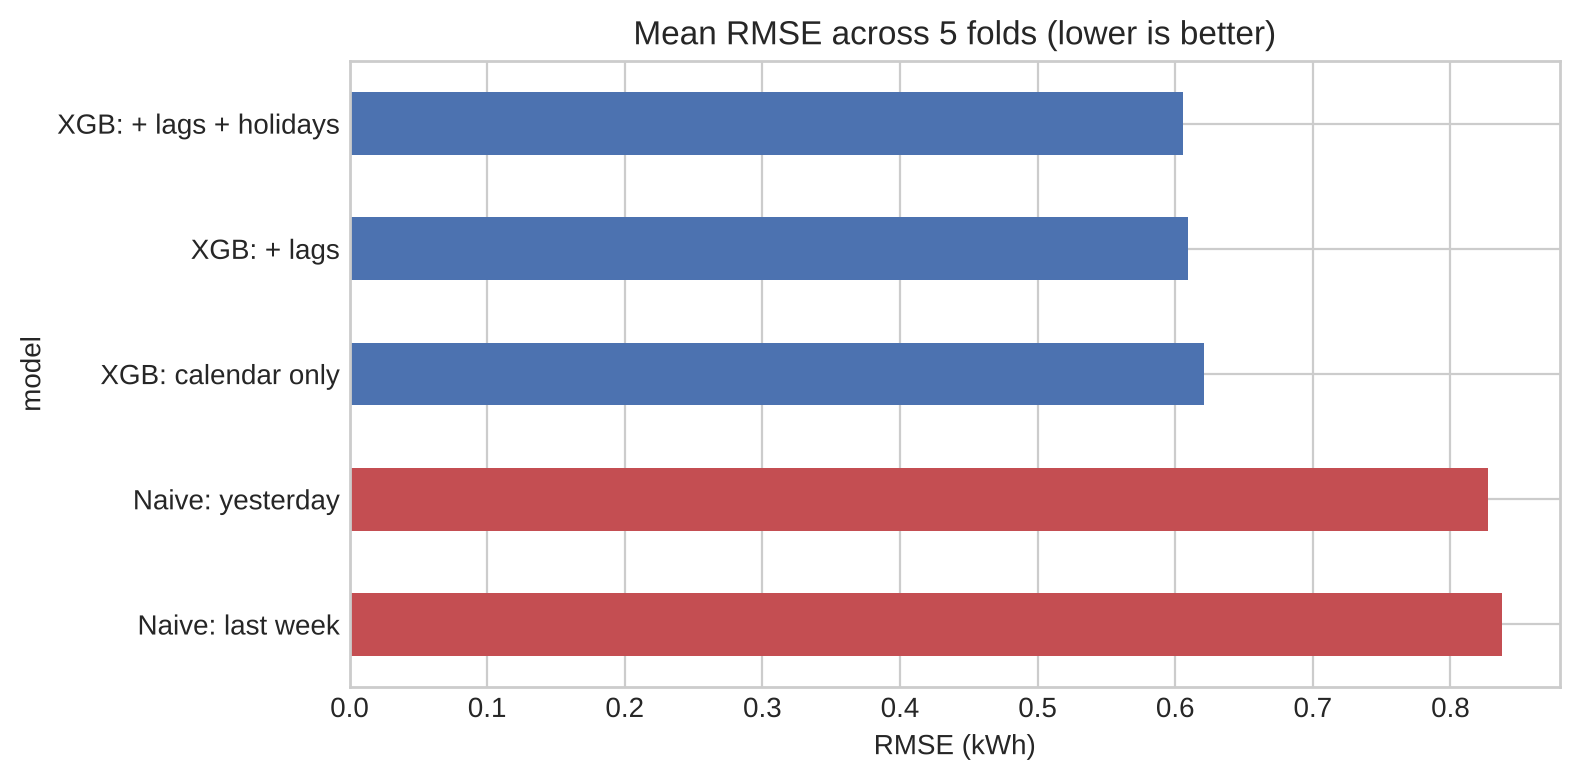

In [13]:
ax = summary['RMSE'].sort_values(ascending=False).plot(kind='barh', figsize=(8, 4),
        color=['#C44E52', '#C44E52', '#4C72B0', '#4C72B0', '#4C72B0'])
ax.set(title='Mean RMSE across 5 folds (lower is better)', xlabel='RMSE (kWh)')
plt.tight_layout(); plt.savefig(FIG_DIR / 'model_comparison.png', dpi=120); plt.show()

## 7. What did the model learn?

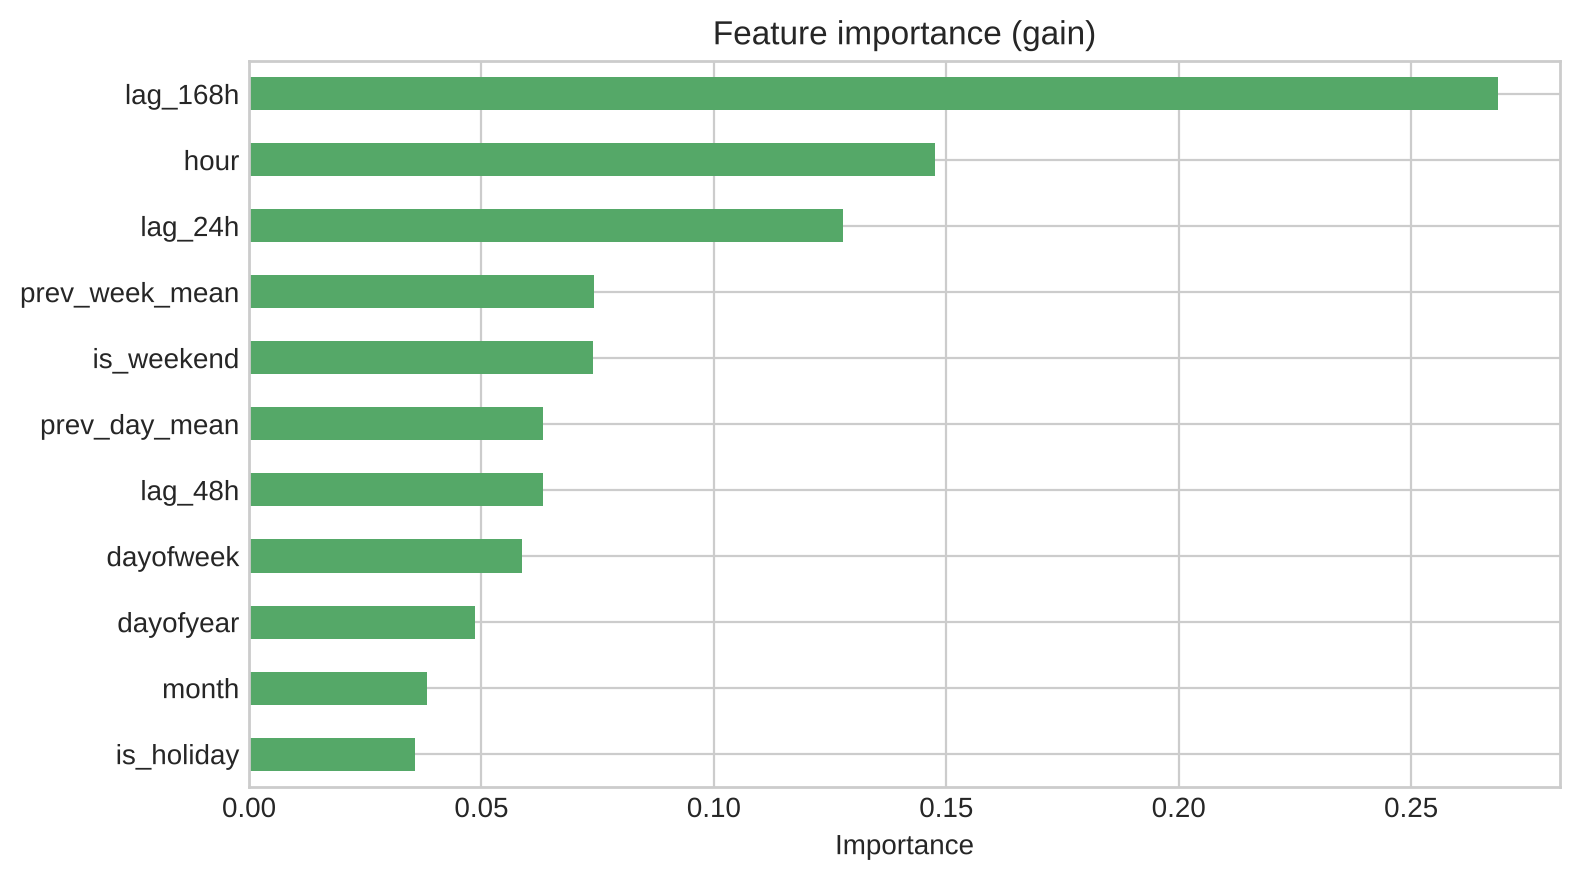

In [14]:
final_feats = FEATURE_SETS['XGB: + lags + holidays']
fit, val = data.iloc[:-24 * 30], data.iloc[-24 * 30:]
final_model = xgb.XGBRegressor(**XGB_PARAMS)
final_model.fit(fit[final_feats], fit['kwh'], eval_set=[(val[final_feats], val['kwh'])], verbose=False)

imp = pd.Series(final_model.feature_importances_, index=final_feats).sort_values()
ax = imp.plot(kind='barh', figsize=(8, 4.5), color='#55A868')
ax.set(title='Feature importance (gain)', xlabel='Importance')
plt.tight_layout(); plt.savefig(FIG_DIR / 'feature_importance.png', dpi=120); plt.show()

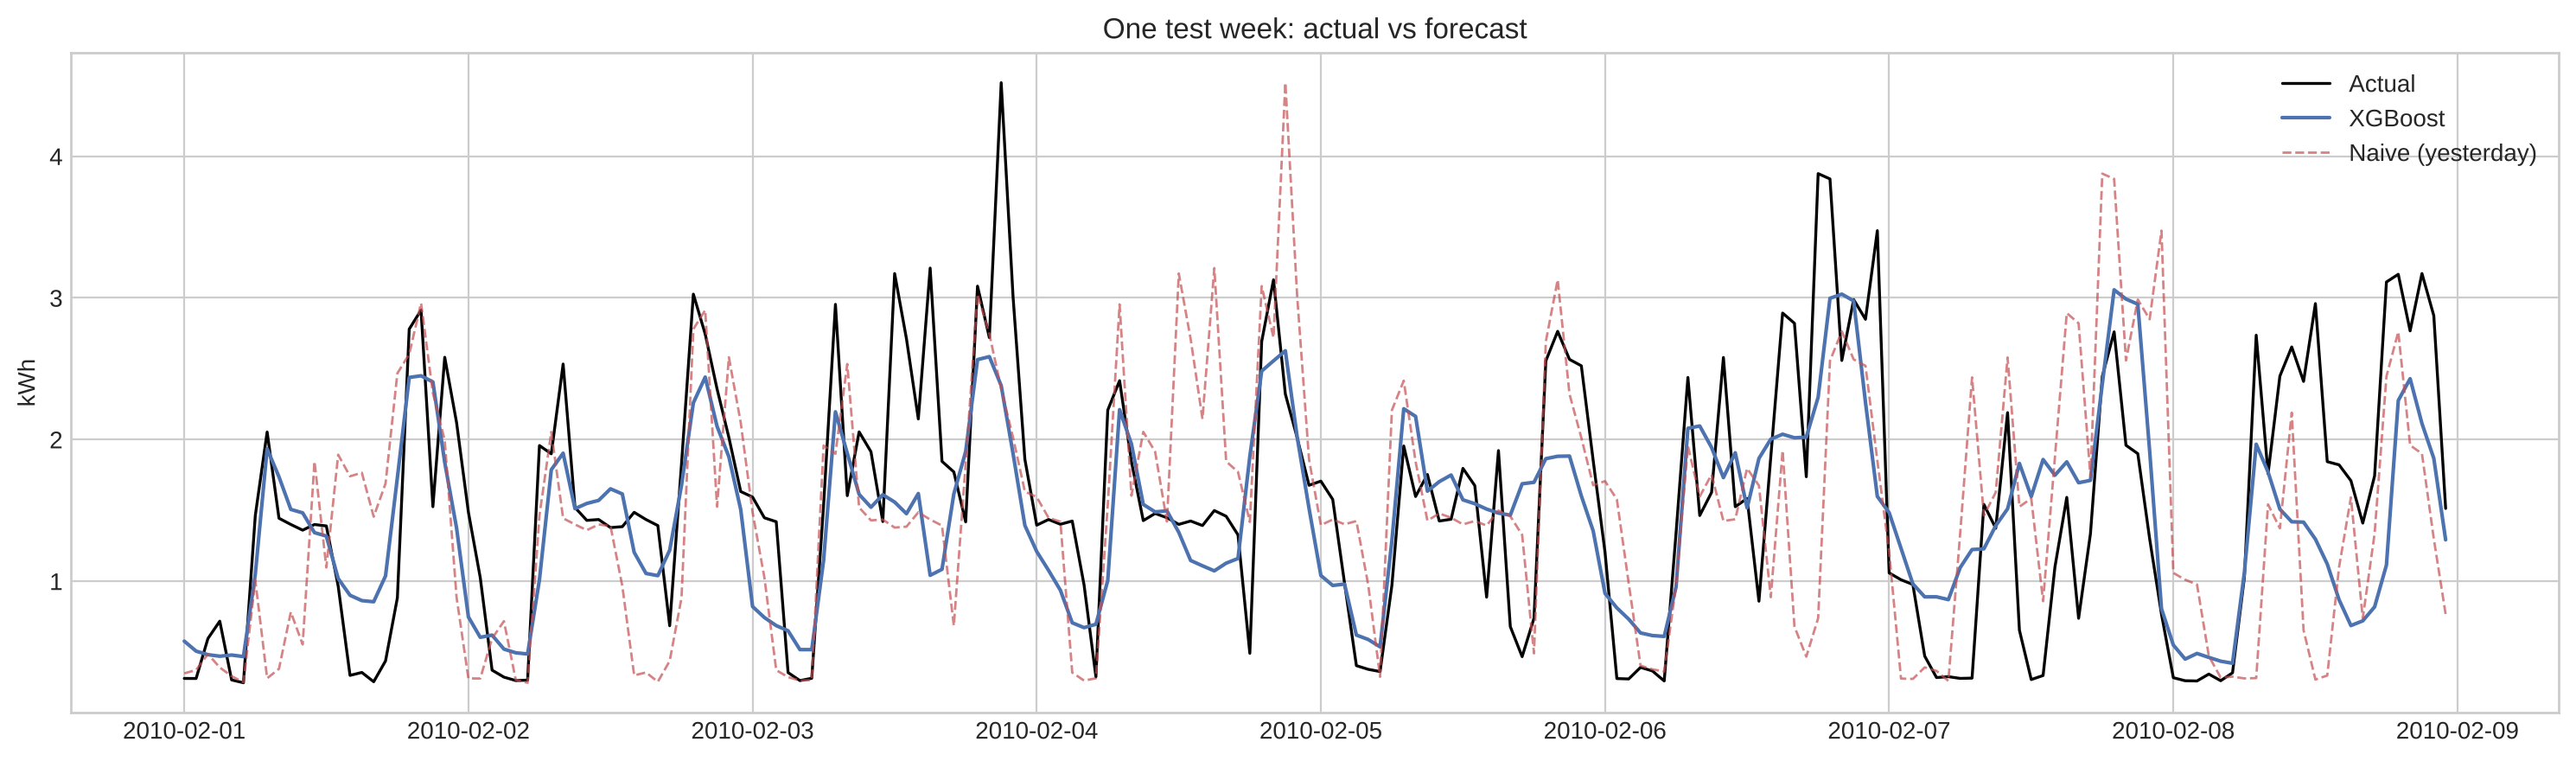

In [15]:
week = oof.loc['2010-02-01':'2010-02-08']
fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(week.index, week.actual, label='Actual', color='black', lw=1.2)
ax.plot(week.index, week.pred, label='XGBoost', color='#4C72B0', lw=1.5)
ax.plot(week.index, week.naive, label='Naive (yesterday)', color='#C44E52', lw=1, ls='--', alpha=0.7)
ax.set(title='One test week: actual vs forecast', ylabel='kWh'); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / 'forecast_week.png', dpi=120); plt.show()

## 8. Error analysis

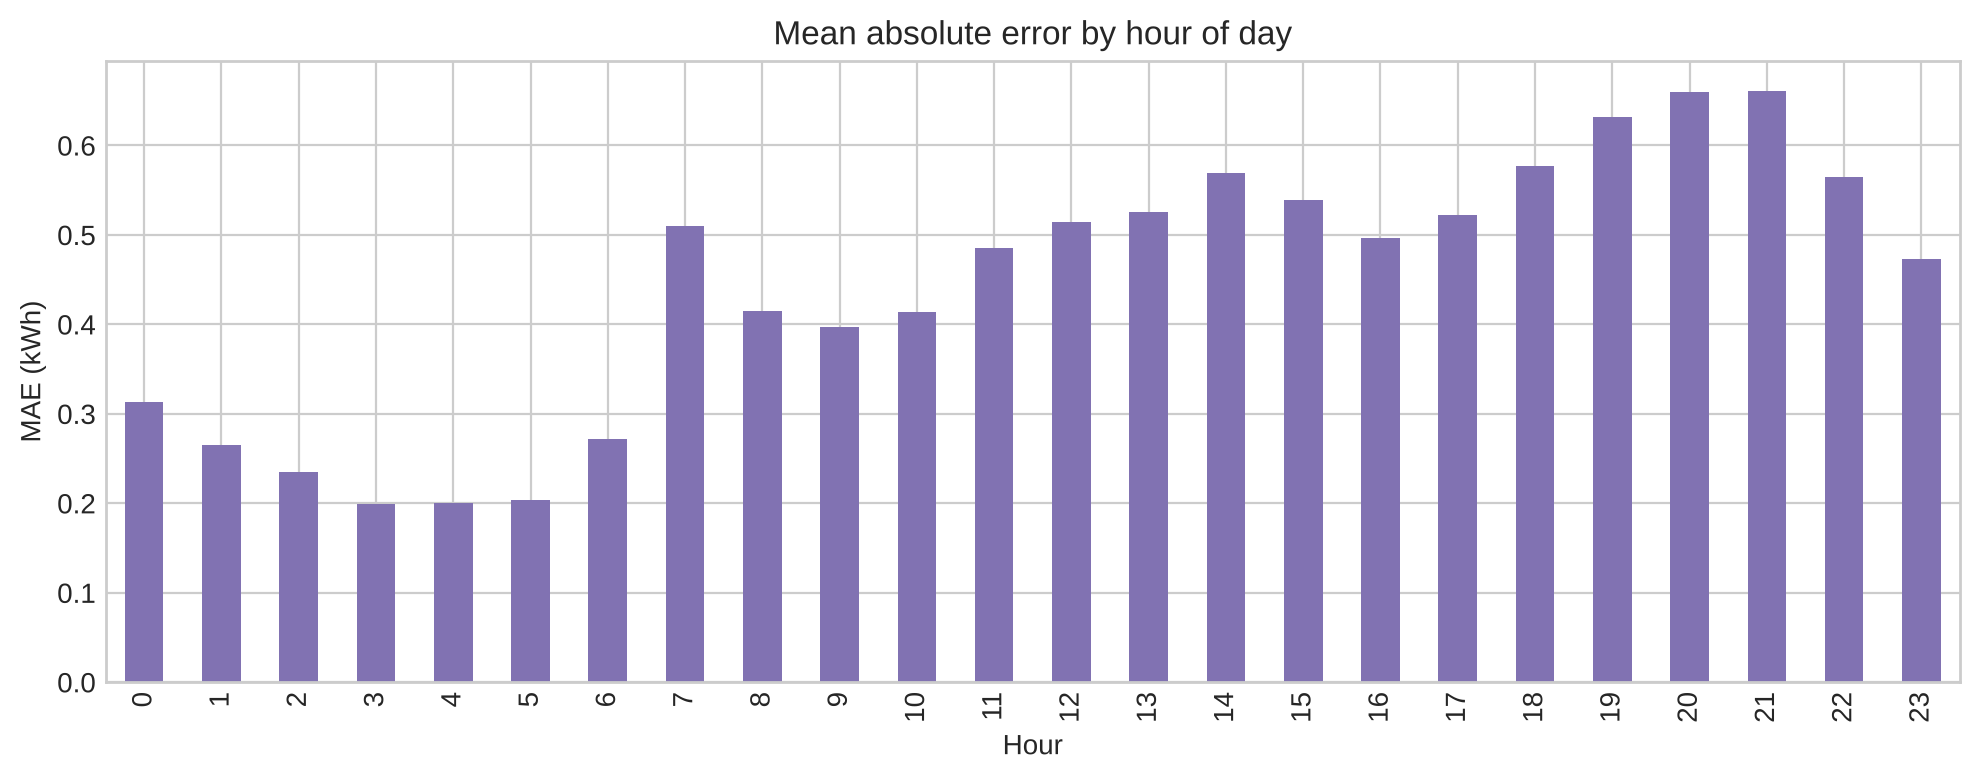

In [16]:
scored = oof[~oof.imputed].copy()
scored['abs_err'] = (scored.actual - scored.pred).abs()
fig, ax = plt.subplots(figsize=(10, 4))
scored.groupby(scored.index.hour)['abs_err'].mean().plot(kind='bar', ax=ax, color='#8172B2')
ax.set(title='Mean absolute error by hour of day', xlabel='Hour', ylabel='MAE (kWh)')
plt.tight_layout(); plt.savefig(FIG_DIR / 'error_by_hour.png', dpi=120); plt.show()

In [17]:
# Worst-forecast days
scored.groupby(scored.index.date)['abs_err'].mean().sort_values(ascending=False).head(5).round(3)

2009-12-24    1.233
2010-10-18    1.000
2010-02-28    0.992
2009-12-19    0.905
2010-10-31    0.898
Name: abs_err, dtype: float64

Errors are smallest overnight and largest in the evening. That's when people's behavior (cooking, laundry, heating) varies most from day to day, and calendar or lag features can't fully predict it.

## 9. Save the final model

In [18]:
Path('models').mkdir(exist_ok=True)
final_model.save_model('models/xgb_day_ahead.json')

# Sanity check: the reloaded model gives the same predictions
reloaded = xgb.XGBRegressor(); reloaded.load_model('models/xgb_day_ahead.json')
assert np.allclose(reloaded.predict(val[final_feats]), final_model.predict(val[final_feats]))
print('Saved models/xgb_day_ahead.json')

Saved models/xgb_day_ahead.json


## 10. Conclusions

- XGBoost with calendar, lag, and holiday features beats the best naive baseline in **every fold** (see the per-fold table).
- **Calendar features do most of the work.** Hour, weekday, and season alone cut RMSE by about 25% versus the naive baseline. Lags add a smaller, consistent gain (about 2 more points). The model leans heavily on `lag_168h` (top importance), but much of that information overlaps with the calendar features.
- **Holidays add only a small gain.** There are only about 11 holidays a year, and household behavior on those days varies.

**Limitations and next steps**
- No weather data: temperature likely drives winter heating. Adding it is the obvious next improvement.
- This is one household. Results won't carry over directly to other homes or to grid-level load.
- Deployment idea: store the data in S3, run a scheduled Lambda that generates tomorrow's forecast, and provision everything with Terraform.